# Pre-processing: from benchmark CSVs to matcher input

Milestone 3 of *Evaluating lineage link prediction with Valentine*.

The exploratory analysis (`01_eda.ipynb`) showed what has to be fixed before Valentine can be run on the
benchmark. This notebook applies these fixes with the functions in `src/preprocessing.py` and writes the
result to `data/processed/` (git-ignored, recreated by running this notebook).

| step | why (finding) | function |
|---|---|---|
| 1. Repair broken rows | line breaks inside values split two `Employees` rows into four | `repair_broken_rows` |
| 2. Remove non-data columns | images (`Picture`, `Photo`) are not data; `GlobalID` / `ParentGID` are written by the lineage tracking and reveal the links | `non_data_columns` |
| 3. Normalise values | the same value is written in different ways (`32,38` / `32.3800`, `00:00:00.000`, padded `CHAR` values) | `normalise_value` |
| 4. Ground truth and candidate pairs | table-level links (bridged over temporary tables without data), labelled pairs, hard negatives | `candidate_pairs` |
| 5. Table names | Valentine's schema-based matchers also compare table names | `table_names` |

What we deliberately do **not** change:

* **column names**: renamed columns are part of what we want to evaluate;
* the **mislabelled column** in `multi` (`TableFulfillmentLeads.CustomerID` holds order IDs, EDA 1.2): it is a
  real data-quality problem that a matcher has to cope with;
* the **rows**: the largest table has 2,155 rows, so no sampling is needed. When running Valentine we will pass
  `instance_sample_size=None`, because its default (1,000 random rows per table) would break the value overlap
  between a table and the tables derived from it.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path("..", "src").resolve()))

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

from eda import PAIR_LABELS, evaluation_links, pair_label, pair_scores
from lineage_data import load_all
from preprocessing import (base_name, candidate_pairs, normalise_value, preprocess_all,
                           repair_broken_rows, save, table_names)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 70)

FIGURES = Path("..", "docs", "figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Same chart style as the EDA: blue marks lineage, neutral greys everything else.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, LIGHT_GREY, MUTED, GRID, SURFACE = "#898781", "#c3c2b7", "#52514e", "#e1e0d9", "#ffffff"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 8,
    "axes.edgecolor": LIGHT_GREY, "axes.labelcolor": MUTED, "axes.titlesize": 8.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

raw = load_all()                                       # as read by lineage_data.py
clean, log = preprocess_all(raw)                       # steps 1-3
no_norm, _ = preprocess_all(raw, normalise=False)      # steps 1 and 2 only (to measure step 3)

## 1. Repair broken rows

`Employees.csv` has 11 rows for 9 employees. The address of two employees contains a line break, so the reader
creates one row with the first part of the address and a second row that starts with the rest of the address and
continues with the remaining fields, shifted by one position.

In [2]:
employees = raw["train"].tables["employees"]
print("rows before:", len(employees))
employees[["EmployeeID", "LastName", "FirstName", "Address", "City", "Country"]].iloc[4:10].map(
    lambda v: v[:35] + "..." if isinstance(v, str) and len(v) > 35 else v)

rows before: 11


,EmployeeID,LastName,FirstName,Address,City,Country
4,5,Buchanan,Steven,14 Garrett Hill,London,UK
5,6,Suyama,Michael,Coventry House,NaN,NaN
6,Miner Rd.,London,NaN, /    \r   ! ÿÿÿÿBitmap Image Pa...,Michael is a graduate of Sussex Uni...,NaN
7,7,King,Robert,Edgeham Hollow,NaN,NaN
8,Winchester Way,London,NaN, /    \r   ! ÿÿÿÿBitmap Image Pa...,Robert King served in the Peace Cor...,NaN
9,8,Callahan,Laura,4726 - 11th Ave. N.E.,Seattle,USA


In [3]:
repaired, merged = repair_broken_rows(employees)
print("rows merged:", merged, "| rows after:", len(repaired))
repaired[["EmployeeID", "LastName", "FirstName", "Address", "City", "Country", "ReportsTo"]]

rows merged: 2 | rows after: 9


,EmployeeID,LastName,FirstName,Address,City,Country,ReportsTo
0,1,Davolio,Nancy,507 - 20th Ave. E.Apt. 2A,Seattle,USA,2
1,2,Fuller,Andrew,908 W. Capital Way,Tacoma,USA,NaN
2,3,Leverling,Janet,722 Moss Bay Blvd.,Kirkland,USA,2
3,4,Peacock,Margaret,4110 Old Redmond Rd.,Redmond,USA,2
4,5,Buchanan,Steven,14 Garrett Hill,London,UK,2
5,6,Suyama,Michael,Coventry House Miner Rd.,London,UK,5
6,7,King,Robert,Edgeham Hollow Winchester Way,London,UK,5
7,8,Callahan,Laura,4726 - 11th Ave. N.E.,Seattle,USA,2
8,9,Dodsworth,Anne,7 Houndstooth Rd.,London,UK,5


Broken rows are recognised by a non-numeric value in the numeric key column (`EmployeeID`). The fragment is
appended to the last filled field of the row before (`Coventry House` + `Miner Rd.`), and the following fields are
moved back to their columns. Without the repair the binary photo ends up in `Address` and the notes in `City`,
which adds wrong values to the columns that `vwEmployeeHierarchy` and `vwOrderEmployeeContext` are derived from.
The same file is used in `train` and `test`; `multi` has no `Employees` table.

## 2. Remove columns that are not data

In [4]:
removed = log[log.step.str.startswith("2.")]
removed.assign(column=removed.detail.str.split(": ").str[0], reason=removed.detail.str.split(": ").str[1])[
    ["split", "table", "column", "reason"]].reset_index(drop=True)

,split,table,column,reason
0,train,Categories,Picture,binary content (image)
1,train,Employees,Photo,binary content (image)
2,train,FinalAtRiskLog,ParentGID,lineage bookkeeping ID
3,train,TableFulfillmentLeads,GlobalID,lineage bookkeeping ID
4,test,Categories,Picture,binary content (image)
5,test,Employees,Photo,binary content (image)
6,multi,FinalAtRiskLog,GlobalID,lineage bookkeeping ID
7,multi,FinalOrderDetails,GlobalID,lineage bookkeeping ID
8,multi,OrderDetailsDummy,GlobalID,lineage bookkeeping ID
9,multi,TableFulfillmentLeads,GlobalID,lineage bookkeeping ID


* **Images.** `Categories.Picture` and `Employees.Photo` are OLE/bitmap images exported as text (values of up
  to 22,000 characters with control characters). They are not used by any scenario and only slow the matchers down.
  A column is treated as binary when at least half of its values contain control characters.
* **Lineage bookkeeping IDs.** `GlobalID` and `ParentGID` are added by the benchmark's lineage tracking, not by
  the scenarios. They are copied unchanged from a temporary table to the final table, so a value-based matcher
  would find the link through them, evidence that does not exist in a real database without lineage tracking:

In [5]:
multi = raw["multi"]
gid = {n: set(df["GlobalID"].dropna()) for n, df in multi.tables.items() if "GlobalID" in df}
multi_links = evaluation_links(multi)
leaks = [{"source": multi.display[s], "target": multi.display[t],
          "share of target GlobalIDs found in source": round(len(gid[s] & gid[t]) / len(gid[t]), 2),
          "relation": pair_label(multi, multi_links, s, t)}
         for s in gid for t in gid if s != t and gid[t] and gid[s] & gid[t]]
pd.DataFrame(leaks)

,source,target,share of target GlobalIDs found in source,relation
0,FinalAtRiskLog,tempAtRisk,1.0,reverse
1,FinalOrderDetails,tempOrderSummary,1.0,reverse
2,tempAtRisk,FinalAtRiskLog,1.0,lineage
3,tempOrderSummary,FinalOrderDetails,1.0,lineage


In `train`, `TableFulfillmentLeads.GlobalID` holds the numbers 1-63, small integers that also occur in many
unrelated key columns. Removing these columns therefore avoids both leaked true positives and extra false positives.

## 3. Normalise values

Instance-based matchers compare values as strings, so `32,38` and `32.38` are different values. The benchmark
writes numbers, dates and fixed-width text in several ways:

In [6]:
examples = ["32,38", "14.0000", "0.0", "1996-07-04 00:00:00", "1996-07-04 00:00:00.000",
            "2025-12-29 05:57:49.253", "Eastern                                           ", "05021", "Chai"]
pd.DataFrame({"raw value": [repr(v) for v in examples], "normalised": [repr(normalise_value(v)) for v in examples]})

,raw value,normalised
0,"'32,38'",'32.38'
1,'14.0000','14'
2,'0.0','0'
3,'1996-07-04 00:00:00','1996-07-04'
4,'1996-07-04 00:00:00.000','1996-07-04'
5,'2025-12-29 05:57:49.253','2025-12-29 05:57:49'
6,'Eastern ','Eastern'
7,'05021','05021'
8,'Chai','Chai'


In [7]:
rewritten = log[log.step.str.startswith("3.")].groupby("split")["count"].sum()
total = pd.Series({s.name: int(sum(df.notna().sum().sum() for df in s.tables.values())) for s in clean.values()})
pd.DataFrame({"values rewritten": rewritten, "share of all values (%)": (100 * rewritten / total).round(1)}).reindex(["train", "test", "multi"])

,values rewritten,share of all values (%)
split,,
train,9539,28.3
test,6923,27.9
multi,15146,30.9


Normalisation is applied the same way to every table and only rewrites the *spelling*: leading zeros
(`05021`), text and times other than midnight are kept. To see what it changes for the matching task we recompute
the value score of the EDA (share of the target's values found in the source, averaged over its columns) for all
ordered table pairs, before and after pre-processing.

In [8]:
scores = {}
for stage, splits in [("raw", raw), ("without step 3", no_norm), ("pre-processed", clean)]:
    scores[stage] = pd.concat([pair_scores(s) for s in splits.values()], ignore_index=True)

compare = pd.DataFrame({stage: df.groupby("label").value_mean.median() for stage, df in scores.items()}).reindex(PAIR_LABELS)
compare.round(3)

,raw,without step 3,pre-processed
label,,,
lineage,0.667,0.667,0.667
reverse,0.352,0.352,0.352
indirect,0.313,0.333,0.333
sibling,0.545,0.590,0.590
unlogged,0.116,0.107,0.107
unrelated,0.143,0.149,0.151


In [9]:
keys = ["split", "source", "target"]
links_before_after = (scores["raw"][scores["raw"].label == "lineage"][keys + ["value_mean"]]
                      .merge(scores["pre-processed"][keys + ["value_mean"]], on=keys, suffixes=("_raw", "_clean")))
changed = links_before_after[(links_before_after.value_mean_clean - links_before_after.value_mean_raw).abs() > 0.005]
changed.sort_values("value_mean_raw").round(2).reset_index(drop=True)

,split,source,target,value_mean_raw,value_mean_clean
0,multi,vwOrderTotals,TableOrderCategories,0.25,0.50
1,multi,OrderDetails,vwOrderTotals,0.50,0.51
2,multi,TableFulfillmentLeads,tempAtRisk,0.75,1.00
3,multi,OrderSummary,tempOrderSummary,0.75,1.00
4,multi,Orders,OrderDetailsDummy,0.75,1.00
5,multi,tempAtRisk,FinalAtRiskLog,0.80,0.75
6,train,vwOrderFulfillment,TableFulfillmentLeads,0.83,1.00
7,multi,vwOrderFulfillment,TableFulfillmentLeads,0.83,1.00


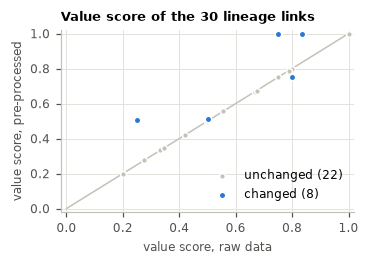

In [10]:
fig, ax = plt.subplots(figsize=(3.4, 2.45))
ax.plot([0, 1], [0, 1], color=LIGHT_GREY, linewidth=1)
same = links_before_after.drop(changed.index)
ax.scatter(same.value_mean_raw, same.value_mean_clean, s=14, color=LIGHT_GREY, edgecolors=SURFACE, linewidths=1,
           label=f"unchanged ({len(same)})", zorder=2)
ax.scatter(changed.value_mean_raw, changed.value_mean_clean, s=18, color=BLUE, edgecolors=SURFACE, linewidths=1,
           label=f"changed ({len(changed)})", zorder=3)
ax.set_xlabel("value score, raw data")
ax.set_ylabel("value score, pre-processed")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="lower right")
ax.set_title("Value score of the 30 lineage links")
fig.tight_layout()
fig.savefig(FIGURES / "pre_01_value_scores.png")
plt.show()

Most links keep their score; the ones that change move up (the points above the diagonal). The gains come from
two sources: removing `GlobalID`, a target column that had no counterpart in the source (e.g.
`vwOrderFulfillment -> TableFulfillmentLeads`, 0.83 -> 1.00), and normalisation, which makes the amounts of
`vwOrderTotals` findable in `TableOrderCategories` (0.25 -> 0.50). The one link that goes down,
`tempAtRisk -> FinalAtRiskLog`, had been helped by the leaked `GlobalID`. For unrelated pairs the median stays
about the same, so pre-processing makes the signal cleaner without making unrelated tables look alike.

## 4. Ground truth: evaluable lineage links

Empty tables (e.g. `CustomerDemographics`, `FinalAtRiskLog` in `train`) are kept in the cleaned splits but left out
of the evaluation by `eda.usable`, as in the EDA.

In [11]:
links = pd.DataFrame([{"split": s.name, "source": s.display[a], "target": s.display[b], "link": kind}
                      for s in clean.values() for (a, b), kind in sorted(evaluation_links(s).items())])
links.groupby(["split", "link"]).size().unstack(fill_value=0).reindex(["train", "test", "multi"])

link,bridged,direct
split,,
train,2,9
test,1,4
multi,0,14


In [12]:
links[links.link == "bridged"].reset_index(drop=True)

,split,source,target,link
0,train,TableRegionalAssignments,FinalManagerialSalesAudit,bridged
1,train,TableSupervisionStaging,FinalSupervisionAudit,bridged
2,test,TableInventoryStaging,FinalProcurementAudit,bridged


The 30 links are the positives of the evaluation. 27 are logged directly; 3 lead into a temporary table
(`##TempJoinBuffer`, `##TempSupervisionBuffer`, `##TempProcurementBuffer`) that was dropped before the export, so
its source and target are linked directly (`A -> ##Temp -> B` becomes `A -> B`), as explained in the EDA.

## 5. Candidate pairs

The matchers will score **every ordered pair** of usable tables inside a split, because a real tool does not know
in advance which tables are related. Each pair gets the ground-truth relation of the EDA and two extra tags:

* `hard_negative`: not a link, but close in the lineage graph (`reverse`, `indirect`, `sibling`). These pairs
  share many values with the true links and test whether a matcher can tell the exact link and its direction;
* `small_int_match`: a target column of small integers (0-100, e.g. `EmployeeID`, `ShipVia`) is fully contained
  in a source column, the main cause of high value scores for unrelated pairs (EDA 2.3).

In [13]:
pairs = pd.concat([candidate_pairs(s) for s in clean.values()], ignore_index=True)
overview = pairs.groupby("split").agg(
    tables=("source", "nunique"),
    pairs=("label", "size"),
    lineage=("is_lineage", "sum"),
    hard_negatives=("hard_negative", "sum"),
    small_int_match=("small_int_match", "sum"),
).reindex(["train", "test", "multi"])
overview.loc["total"] = overview.sum()
overview["lineage_%"] = (100 * overview.lineage / overview.pairs).round(1)
overview

,tables,pairs,lineage,hard_negatives,small_int_match,lineage_%
split,,,,,,
train,21,420,11,37,153,2.6
test,14,182,5,19,84,2.7
multi,16,240,14,64,4,5.8
total,51,842,30,120,241,3.6


In [14]:
pairs.groupby(["direction", "label"]).size().unstack(fill_value=0).reindex(columns=PAIR_LABELS)

label,lineage,reverse,indirect,sibling,unlogged,unrelated
direction,,,,,,
derived -> derived,16,16,24,6,34,132
derived -> original,0,14,30,0,22,125
original -> derived,14,0,30,0,22,125
original -> original,0,0,0,0,0,232


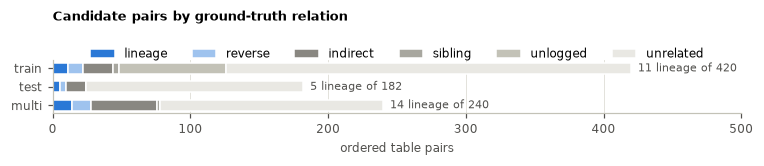

In [15]:
counts = pairs.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(index=["multi", "test", "train"], columns=PAIR_LABELS)
colors = {"lineage": BLUE, "reverse": "#9fc3ee", "indirect": GREY, "sibling": "#a8a79f", "unlogged": LIGHT_GREY, "unrelated": "#e9e8e3"}
fig, ax = plt.subplots(figsize=(7.0, 1.6))
left = pd.Series(0, index=counts.index)
for label in PAIR_LABELS:
    ax.barh(counts.index, counts[label], left=left, color=colors[label], height=0.6,
            edgecolor=SURFACE, linewidth=1, label=label)
    left += counts[label]
for y, (split, n) in enumerate(counts[["lineage"]].itertuples()):
    ax.text(left[split] + 5, y, f"{n} lineage of {left[split]}", va="center", fontsize=7, color=MUTED)
ax.set_xlim(0, 500)
ax.grid(axis="y", visible=False)
ax.set_xlabel("ordered table pairs")
ax.legend(loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.45))
ax.set_title("Candidate pairs by ground-truth relation", pad=26)
fig.tight_layout()
fig.savefig(FIGURES / "pre_02_candidate_pairs.png")
plt.show()

Only 3.6 % of the pairs are lineage links, so accuracy would be meaningless (predicting "no link" everywhere gives
96 %). We therefore evaluate the matchers as **rankers**: PR-AUC and AUROC over all pairs, and Hits@k / MRR per
target table, the metrics of the baseline paper. `derived -> original` and `original -> original` pairs can never be
links in this benchmark, but they stay in the candidate set: telling them apart is part of the task, and results
will also be reported for `original -> derived` and `derived -> derived` pairs separately.

## 6. Table names for the "table names on/off" experiment

Valentine's schema-based matchers (COMA, Cupid, Similarity Flooding) compare table names as well as column names.
Object names in the benchmark carry their type (`vw`, `Table`, `temp`, `Final`) and often the name of their source,
which could make the task easier than in a real database. We prepare three variants:

In [16]:
names = table_names(clean["multi"], "raw")
pd.DataFrame({"raw": names, "base": table_names(clean["multi"], "base")}).query("raw != base").reset_index(drop=True)

,raw,base
0,FinalAtRiskLog,AtRiskLog
1,FinalHighValueReport,HighValueReport
2,FinalOrderDetails,OrderDetails
3,TableFulfillmentLeads,FulfillmentLeads
4,TableOrderCategories,OrderCategories
5,tempAtRisk,AtRisk
6,tempHighValue,HighValue
7,tempOrderSummary,OrderSummary
8,vwOrderFulfillment,OrderFulfillment
9,vwOrderTotals,OrderTotals


* `raw`: the name in the database;
* `base`: the name without its type prefix, e.g. `vwOrderFulfillment -> OrderFulfillment`. It can also mislead:
  `FinalOrderDetails` becomes `OrderDetails`, the name of a Northwind table it is **not** derived from;
* `neutral`: no names (`df_names=None`), Valentine then uses `aaa`, `bbb`, ... which share no characters.

## 7. Save

In [17]:
folder = save(clean, pairs, log)
print("written to", folder.relative_to(Path("..").resolve()))
for path in sorted(folder.glob("*.csv")):
    print(f"  {path.name:<24} {len(pd.read_csv(path)):>4} rows")
print(f"  {len(list(folder.glob('*/*.csv')))} cleaned tables in", ", ".join(f"{s}/" for s in clean))

written to data\processed
  pairs.csv                 842 rows
  preprocessing_log.csv      42 rows
  tables.csv                 51 rows
  51 cleaned tables in train/, test/, multi/


## 8. Main outcomes

In [18]:
steps = log.groupby("step")["count"].sum()
outcomes = {
    "broken rows repaired (Employees, train and test)": int(steps.get("1. repair broken rows", 0)),
    "non-data columns removed (images / lineage IDs)": f"{(removed.detail.str.contains('image')).sum()} / {(removed.detail.str.contains('lineage')).sum()}",
    "values rewritten by normalisation": int(steps.get("3. normalise values", 0)),
    "lineage links whose value score changed": f"{len(changed)} of {len(links_before_after)} ({(changed.value_mean_clean > changed.value_mean_raw).sum()} up)",
    "median value score lineage vs unrelated, raw": f"{compare.loc['lineage', 'raw']:.2f} vs {compare.loc['unrelated', 'raw']:.2f}",
    "median value score lineage vs unrelated, pre-processed": f"{compare.loc['lineage', 'pre-processed']:.2f} vs {compare.loc['unrelated', 'pre-processed']:.2f}",
    "evaluable links (direct / bridged)": f"{(links.link == 'direct').sum()} / {(links.link == 'bridged').sum()}",
    "candidate pairs (train/test/multi)": "/".join(str(int(n)) for n in overview.pairs[:3]),
    "share of lineage pairs (%)": overview.loc["total", "lineage_%"],
    "hard negatives / small-integer matches": f"{int(overview.loc['total', 'hard_negatives'])} / {int(overview.loc['total', 'small_int_match'])}",
}
pd.Series(outcomes, name="value").to_frame()

,value
"broken rows repaired (Employees, train and test)",4
non-data columns removed (images / lineage IDs),4 / 8
values rewritten by normalisation,31608
lineage links whose value score changed,8 of 30 (7 up)
"median value score lineage vs unrelated, raw",0.67 vs 0.14
"median value score lineage vs unrelated, pre-processed",0.67 vs 0.15
evaluable links (direct / bridged),27 / 3
candidate pairs (train/test/multi),420/182/240
share of lineage pairs (%),3.6
hard negatives / small-integer matches,120 / 241
